In [1]:
# ============================================================
# AERIS-X — C-MAPSS Data Ingestion and Initial Understanding
# ============================================================
#
# Purpose:
# Load NASA C-MAPSS FD001 telemetry and perform the initial
# structural and quality checks required before preprocessing
# and machine-learning experiments.
#
# Raw telemetry is kept unchanged in data/raw/ to preserve
# reproducibility across future preprocessing and modeling
# experiments.
# ============================================================


# -------------------------
# Project and module setup
# -------------------------

import sys
from pathlib import Path

import pandas as pd


# Resolve the project root dynamically so that the notebook
# remains portable across development environments.
PROJECT_ROOT = Path.cwd().parent


# Make the reusable AERIS-X source modules available to the notebook.
sys.path.append(str(PROJECT_ROOT / "src"))


# Import the data-ingestion and validation components used
# throughout the AERIS-X telemetry pipeline.
from aeris.data.cmapss import load_cmapss_file
from aeris.data.validation import validate_telemetry
from aeris.data.quality import generate_quality_report


# -------------------------
# Load raw C-MAPSS telemetry
# -------------------------

# Read the original FD001 training telemetry directly from
# the raw-data directory. The source file is not modified.
data_path = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "train_FD001.txt"
)


# Convert the raw NASA telemetry file into the standardized
# AERIS-X DataFrame representation.
df = load_cmapss_file(data_path)


# Preview the loaded records to verify successful ingestion
# before running validation and data-quality analysis.
print(df.head())

   engine_id  cycle  setting_1  setting_2  setting_3  sensor_1  sensor_2  \
0          1      1    -0.0007    -0.0004      100.0    518.67    641.82   
1          1      2     0.0019    -0.0003      100.0    518.67    642.15   
2          1      3    -0.0043     0.0003      100.0    518.67    642.35   
3          1      4     0.0007     0.0000      100.0    518.67    642.35   
4          1      5    -0.0019    -0.0002      100.0    518.67    642.37   

   sensor_3  sensor_4  sensor_5  ...  sensor_12  sensor_13  sensor_14  \
0   1589.70   1400.60     14.62  ...     521.66    2388.02    8138.62   
1   1591.82   1403.14     14.62  ...     522.28    2388.07    8131.49   
2   1587.99   1404.20     14.62  ...     522.42    2388.03    8133.23   
3   1582.79   1401.87     14.62  ...     522.86    2388.08    8133.83   
4   1582.85   1406.22     14.62  ...     522.19    2388.04    8133.80   

   sensor_15  sensor_16  sensor_17  sensor_18  sensor_19  sensor_20  sensor_21  
0     8.4195       0.03

In [2]:
# Validate the loaded telemetry against the basic structural
# requirements defined for the AERIS-X data ingestion layer.
# The function raises an error if the dataset is empty, required
# fields are missing, cycle values are invalid, or duplicate
# engine/cycle records are detected.
validate_telemetry(df)


# If execution reaches this point without an exception, the
# telemetry has passed all structural validation checks.
print("Telemetry validation passed.")

Telemetry validation passed.


In [3]:
# Generate a machine-readable summary of the telemetry dataset's
# quality characteristics, including dataset size, engine count,
# missing values, duplicate records, and the number of sensor columns.
report = generate_quality_report(df)


# Display the quality report so that the dataset can be inspected
# before moving to deeper telemetry and sensor analysis.
report

{'rows': 20631,
 'columns': 26,
 'engines': 100,
 'missing_values': 0,
 'duplicate_rows': 0,
 'duplicate_engine_cycles': 0,
 'sensor_columns': 21}

In [4]:
# Count the number of unique engines represented in the dataset.
# This establishes how many independent engine trajectories are
# available for subsequent degradation analysis and engine-level
# train/test evaluation.
df["engine_id"].nunique()

100

In [5]:
# Determine the final recorded cycle for each engine.
# This gives the length of each engine's observed telemetry
# trajectory and helps us understand how engine lifetimes vary
# across the training dataset.
df.groupby("engine_id")["cycle"].max()

engine_id
1      192
2      287
3      179
4      189
5      269
      ... 
96     336
97     202
98     156
99     185
100    200
Name: cycle, Length: 100, dtype: int64

In [6]:
# Summarize the distribution of the final recorded cycle across
# all engines. This shows the typical trajectory length as well as
# the minimum, maximum, and spread of engine lifetimes in the dataset.
df.groupby("engine_id")["cycle"].max().describe()

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64

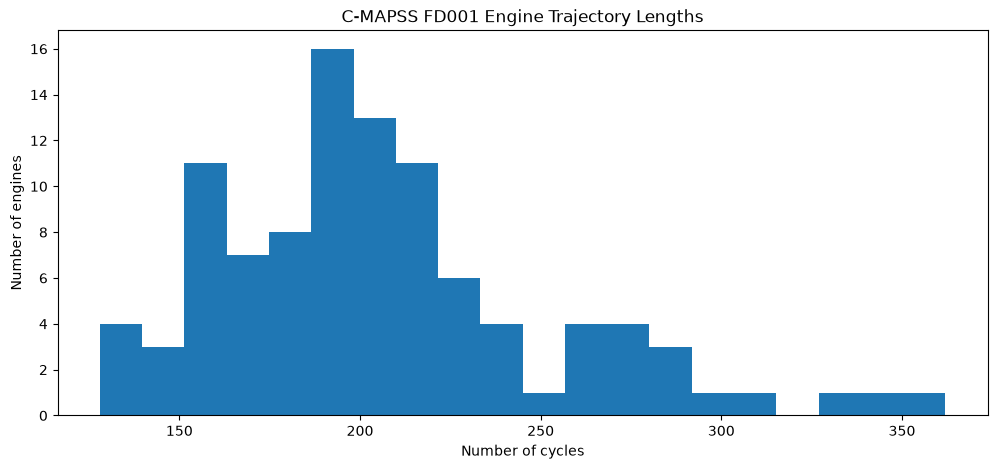

In [7]:
import matplotlib.pyplot as plt

cycles_per_engine = (
    df.groupby("engine_id")["cycle"]
    .max()
)

plt.figure(figsize=(12, 5))

plt.hist(cycles_per_engine, bins=20)

plt.xlabel("Number of cycles")
plt.ylabel("Number of engines")
plt.title("C-MAPSS FD001 Engine Trajectory Lengths")

plt.show()

In [8]:
# Calculate the number of missing values in each telemetry column.
# This provides a column-level completeness check before downstream
# analysis and prevents hidden gaps in the raw sensor data from
# affecting later AERIS-X processing.
missing = df.isna().sum()

# Display only columns containing missing values so that any
# incomplete telemetry fields can be investigated explicitly.
missing[missing > 0]

Series([], dtype: int64)

In [9]:
# Check for completely duplicated telemetry records across all columns.
# This verifies that the raw dataset does not contain repeated rows
# that could distort engine-level analysis or downstream modeling.
df.duplicated().sum()

np.int64(0)

In [10]:
# Verify that each engine has at most one telemetry record per cycle.
# This prevents repeated engine-cycle observations from distorting
# the temporal structure of an engine's degradation trajectory.
df.duplicated(
    subset=["engine_id", "cycle"]
).sum()

np.int64(0)

In [11]:
df.dtypes

engine_id      int64
cycle          int64
setting_1    float64
setting_2    float64
setting_3    float64
sensor_1     float64
sensor_2     float64
sensor_3     float64
sensor_4     float64
sensor_5     float64
sensor_6     float64
sensor_7     float64
sensor_8     float64
sensor_9     float64
sensor_10    float64
sensor_11    float64
sensor_12    float64
sensor_13    float64
sensor_14    float64
sensor_15    float64
sensor_16    float64
sensor_17      int64
sensor_18      int64
sensor_19    float64
sensor_20    float64
sensor_21    float64
dtype: object

In [12]:
# Define the columns that uniquely identify the position of each
# telemetry observation within an engine's operating trajectory.
id_columns = [
    "engine_id",
    "cycle",
]

# Define the engine operating-condition variables provided by the
# C-MAPSS dataset. These settings describe the operating regime
# under which the sensor measurements were recorded.
setting_columns = [
    "setting_1",
    "setting_2",
    "setting_3",
]

# Identify all telemetry measurements programmatically from the
# standardized sensor naming convention. This keeps the pipeline
# adaptable if the number of sensor columns changes in future
# datasets or configurations.
sensor_columns = [
    column
    for column in df.columns
    if column.startswith("sensor_")
]

In [13]:
# Report the finalized telemetry schema so that the expected
# column groups can be verified before beginning sensor-level analysis.
print("ID columns:", id_columns)
print("Settings:", setting_columns)
print("Sensors:", len(sensor_columns))

ID columns: ['engine_id', 'cycle']
Settings: ['setting_1', 'setting_2', 'setting_3']
Sensors: 21


In [14]:
# Generate descriptive statistics for each telemetry sensor and
# transpose the result so that each sensor is represented as a row.
# This provides a compact view of sensor scale, variability, and
# distribution before selecting or engineering sensor features.
sensor_summary = df[sensor_columns].describe().T

# Display the sensor-level statistical summary for inspection.
sensor_summary

,count,mean,std,min,25%,50%,75%,max
sensor_1,20631.0,518.670000,0.000000e+00,518.6700,518.6700,518.6700,518.6700,518.6700
sensor_2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
sensor_3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
sensor_4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
sensor_5,20631.0,14.620000,5.329200e-15,14.6200,14.6200,14.6200,14.6200,14.6200
sensor_6,20631.0,21.609803,1.388985e-03,21.6000,21.6100,21.6100,21.6100,21.6100
sensor_7,20631.0,553.367711,8.850923e-01,549.8500,552.8100,553.4400,554.0100,556.0600
sensor_8,20631.0,2388.096652,7.098548e-02,2387.9000,2388.0500,2388.0900,2388.1400,2388.5600
sensor_9,20631.0,9065.242941,2.208288e+01,9021.7300,9053.1000,9060.6600,9069.4200,9244.5900
sensor_10,20631.0,1.300000,0.000000e+00,1.3000,1.3000,1.3000,1.3000,1.3000


In [15]:
# Measure the standard deviation of each sensor to quantify how
# much its readings vary across the complete training telemetry.
# Sensor variability helps identify measurements that contain
# meaningful changes rather than remaining nearly constant.

sensor_std = df[sensor_columns].std()

# Rank sensors from lowest to highest variability so that sensors
# with limited or substantial variation can be identified for
# further telemetry analysis.

sensor_std.sort_values()

sensor_1     0.000000e+00
sensor_10    0.000000e+00
sensor_19    0.000000e+00
sensor_18    0.000000e+00
sensor_16    3.469531e-18
sensor_5     5.329200e-15
sensor_6     1.388985e-03
sensor_15    3.750504e-02
sensor_8     7.098548e-02
sensor_13    7.191892e-02
sensor_21    1.082509e-01
sensor_20    1.807464e-01
sensor_11    2.670874e-01
sensor_2     5.000533e-01
sensor_12    7.375534e-01
sensor_7     8.850923e-01
sensor_17    1.548763e+00
sensor_3     6.131150e+00
sensor_4     9.000605e+00
sensor_14    1.907618e+01
sensor_9     2.208288e+01
dtype: float64

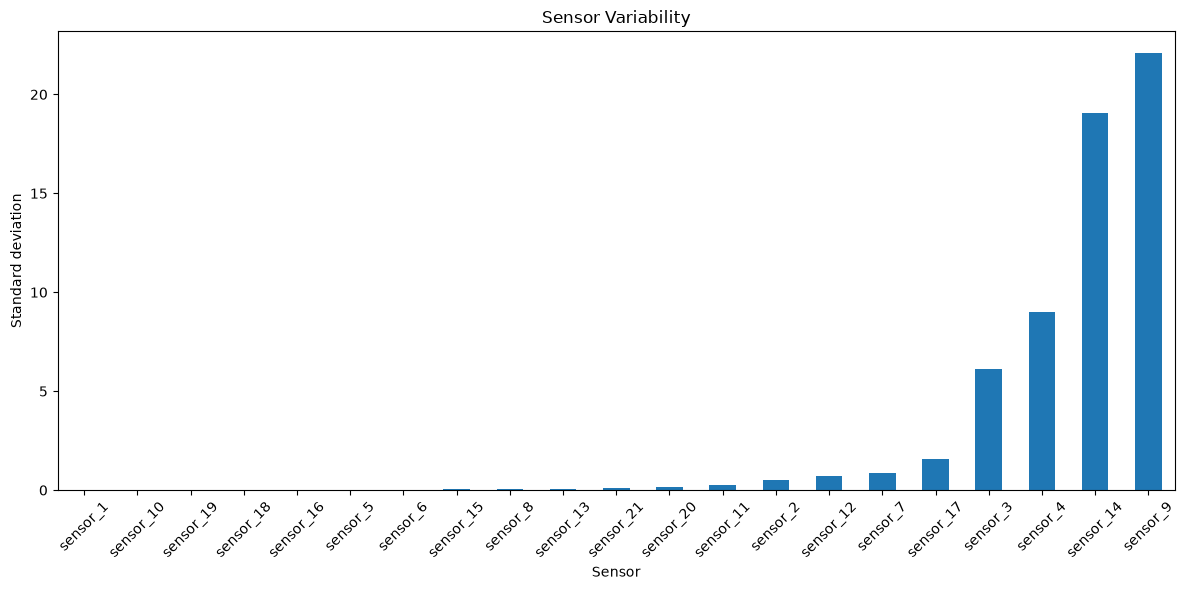

In [16]:
# Visualize the variability of each telemetry sensor to compare
# how strongly different measurements fluctuate across the dataset.
# Ranking sensors by standard deviation makes low- and high-variability
# measurements easier to identify during the initial sensor analysis.
plt.figure(figsize=(12, 6))

sensor_std.sort_values().plot(kind="bar")

plt.xlabel("Sensor")
plt.ylabel("Standard deviation")
plt.title("Sensor Variability")

# Rotate sensor labels to keep the chart readable and prevent overlap.
plt.xticks(rotation=45)

# Adjust the layout so that axis labels and the chart title remain visible.
plt.tight_layout()

# Render the sensor-variability visualization for inspection.
plt.show()

In [17]:
# Isolate the complete telemetry trajectory of Engine 1 so that
# its sensor behavior can be analyzed across the engine's observed
# operating cycles.
engine_1 = df[df["engine_id"] == 1]

# Inspect the first observations to confirm that the correct
# engine trajectory has been selected before performing
# sensor-level time-series analysis.
engine_1.head()

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


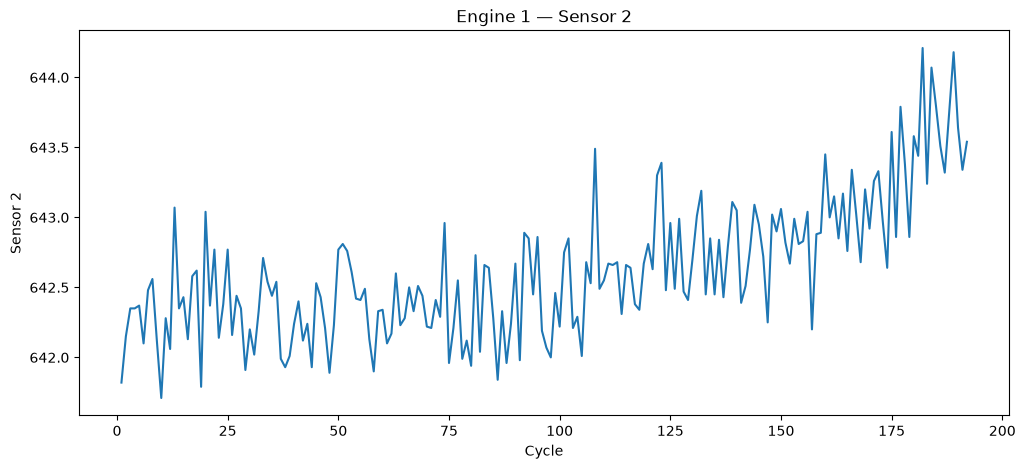

In [18]:
# Visualize the temporal behavior of Sensor 2 across Engine 1's
# observed operating cycles. This helps identify whether the sensor
# exhibits trends, fluctuations, or other degradation-related patterns.
plt.figure(figsize=(12, 5))

plt.plot(
    engine_1["cycle"],
    engine_1["sensor_2"]
)

plt.xlabel("Cycle")
plt.ylabel("Sensor 2")
plt.title("Engine 1 — Sensor 2")

# Render the sensor trajectory for visual inspection.
plt.show()

In [19]:
# Import the reusable sensor-identification utilities from the
# AERIS-X preprocessing layer rather than duplicating sensor-selection
# logic inside the notebook.
from aeris.preprocessing.sensors import (
    get_sensor_columns,
    find_constant_sensors,
)

# Identify all telemetry sensor columns from the standardized
# C-MAPSS schema. These columns will form the candidate feature set
# for subsequent sensor analysis and preprocessing.
sensors = get_sensor_columns(df)

# Detect sensors with effectively zero variance across the training
# telemetry. These signals are candidates for exclusion from the
# initial prognostics feature set, subject to further analysis.
constant_sensors = find_constant_sensors(df)

# Report the total number of detected telemetry sensors and the
# sensors identified as effectively constant.
print("Sensors:", len(sensors))
print("Constant sensors:", constant_sensors)

Sensors: 21
Constant sensors: ['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']


In [20]:
import aeris.preprocessing.sensors as sensors

print("Loaded file:")
print(sensors.__file__)

print("\nAvailable functions:")
print([name for name in dir(sensors) if not name.startswith("_")])

Loaded file:
c:\Users\rajat\AERIS-X\src\aeris\preprocessing\sensors.py

Available functions:
['List', 'find_constant_sensors', 'get_sensor_columns', 'pd', 'select_variable_sensors']


In [21]:
print(hasattr(sensors, "select_variable_sensors"))

True


In [22]:
from pathlib import Path

sensor_file = Path(sensors.__file__)

print(sensor_file.read_text())

from typing import List

import pandas as pd


def get_sensor_columns(df: pd.DataFrame) -> List[str]:
    """
    Return all telemetry sensor columns.
    """

    # Identify sensor measurements using the standardized naming
    # convention established by the AERIS-X C-MAPSS data loader.
    # This avoids hard-coding the complete list of sensor names.
    return [
        column
        for column in df.columns
        if column.startswith("sensor_")
    ]


def find_constant_sensors(
    df: pd.DataFrame,
    tolerance: float = 1e-8,
) -> List[str]:
    """
    Identify sensors with effectively zero variance.
    """

    # Retrieve the telemetry columns that should be evaluated
    # for meaningful variation across the dataset.
    sensor_columns = get_sensor_columns(df)

    # Calculate the standard deviation of each sensor.
    # Sensors with negligible variation provide little changing
    # information for degradation modeling and require further review.
    std = df[sensor_colu

In [23]:
from aeris.preprocessing.sensors import (
    get_sensor_columns,
    find_constant_sensors,
    select_variable_sensors,
)

In [24]:
sensors = get_sensor_columns(df)
constant_sensors = find_constant_sensors(df)
selected_sensors = select_variable_sensors(df)

print("Sensors:", len(sensors))
print("Constant sensors:", constant_sensors)
print("Selected sensors:", len(selected_sensors))
print("Features:", selected_sensors)

Sensors: 21
Constant sensors: ['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Selected sensors: 15
Features: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


In [25]:
selected_sensors = select_variable_sensors(df)

print(selected_sensors)

['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


In [28]:
# Locate the project root by searching for the src/aeris package.
project_root = next(
    (
        path
        for path in [Path.cwd(), *Path.cwd().parents]
        if (path / "src" / "aeris").is_dir()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError("Could not locate the project's src/aeris package.")

src_path = project_root / "src"

if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

from aeris.preprocessing.sensors import (
    select_variable_sensors,
)

from aeris.preprocessing.labels import (
    add_rul_labels,
    add_health_labels,
)

df = add_rul_labels(df)
df = add_health_labels(df)

feature_columns = select_variable_sensors(df)

print("Features:", feature_columns)

Features: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


In [29]:
from aeris.preprocessing.windows import create_sequences

In [30]:
X, y, engine_ids = create_sequences(
    df=df,
    feature_columns=feature_columns,
    target_column="rul",
    window_size=30,
)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Engine IDs:", engine_ids.shape)


X shape: (17731, 30, 15)
y shape: (17731,)
Engine IDs: (17731,)


In [31]:
# Identify the unique engine trajectories available in the training dataset.
# Engine IDs are the unit of separation used to prevent temporal and
# cross-engine information leakage during model development.
engine_ids_unique = df["engine_id"].unique()

print("Total engines:", len(engine_ids_unique))
print("Engine IDs:", engine_ids_unique)

Total engines: 100
Engine IDs: [  1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17  18
  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35  36
  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53  54
  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71  72
  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89  90
  91  92  93  94  95  96  97  98  99 100]


In [32]:
from sklearn.model_selection import train_test_split

# Split complete engine trajectories rather than individual telemetry
# rows or overlapping temporal windows. This prevents information from
# the same engine appearing in both training and validation datasets.
train_engines, val_engines = train_test_split(
    engine_ids_unique,
    test_size=0.2,
    random_state=42,
)

print("Training engines:", len(train_engines))
print("Validation engines:", len(val_engines))

Training engines: 80
Validation engines: 20


In [33]:
# Verify that no engine appears in both partitions.
# Any overlap would invalidate the engine-level split and introduce
# information leakage into validation.
overlap = set(train_engines) & set(val_engines)

print("Engine overlap:", overlap)

assert len(overlap) == 0

print("Engine-level split validated.")

Engine overlap: set()
Engine-level split validated.


In [34]:
from aeris.data.splitting import split_by_engine

train_df, validation_df = split_by_engine(
    df,
    validation_size=0.15,
    random_state=42,
)

In [35]:
print(
    "Training engines:",
    train_df["engine_id"].nunique()
)

print(
    "Validation engines:",
    validation_df["engine_id"].nunique()
)

Training engines: 85
Validation engines: 15


In [36]:
train_engines = set(
    train_df["engine_id"].unique()
)

validation_engines = set(
    validation_df["engine_id"].unique()
)

overlap = train_engines & validation_engines

print("Engine overlap:", overlap)

Engine overlap: set()


In [37]:
assert not overlap, (
    "Data leakage detected: "
    "same engine exists in train and validation."
)

In [38]:
from aeris.preprocessing.sensors import (
    select_variable_sensors,
)

from aeris.preprocessing.normalization import (
    fit_sensor_scaler,
    transform_sensor_data,
)

In [39]:
feature_columns = select_variable_sensors(
    train_df
)

print(
    "Selected sensors:",
    feature_columns
)

Selected sensors: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


In [40]:
scaler = fit_sensor_scaler(
    train_df,
    feature_columns,
)

In [42]:
train_scaled = transform_sensor_data(
    train_df,
    feature_columns,
    scaler,
)

validation_scaled = transform_sensor_data(
    validation_df,
    feature_columns,
    scaler,
)

In [44]:
train_scaled[feature_columns].mean().head()

sensor_2    3.807302e-14
sensor_3   -9.567192e-15
sensor_4   -6.309105e-17
sensor_6    7.623825e-14
sensor_7    2.687355e-14
dtype: float64

In [46]:
train_scaled[feature_columns].std().head()

sensor_2    1.000028
sensor_3    1.000028
sensor_4    1.000028
sensor_6    1.000028
sensor_7    1.000028
dtype: float64

In [47]:
from pathlib import Path

from aeris.preprocessing.normalization import save_scaler

# Persist the fitted training scaler as a reusable preprocessing artifact.
# AERIS-X will later load this exact scaler during validation and inference
# instead of fitting a new transformation on incoming telemetry.
scaler_path = (
    project_root
    / "models"
    / "preprocessing"
    / "cmapss_fd001_scaler.joblib"
)

save_scaler(
    scaler,
    scaler_path,
)

print(f"Scaler saved to: {scaler_path}")

Scaler saved to: c:\Users\rajat\AERIS-X\models\preprocessing\cmapss_fd001_scaler.joblib


In [48]:
from aeris.preprocessing.windows import (
    create_sequences,
)


In [49]:
X_train, y_train, train_sequence_engines = (
    create_sequences(
        df=train_scaled,
        feature_columns=feature_columns,
        target_column="rul",
        window_size=30,
    )
)

In [50]:
X_validation, y_validation, validation_sequence_engines = (
    create_sequences(
        df=validation_scaled,
        feature_columns=feature_columns,
        target_column="rul",
        window_size=30,
    )
)

In [51]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print(
    "X_validation:",
    X_validation.shape,
)

print(
    "y_validation:",
    y_validation.shape,
)

X_train: (15104, 30, 15)
y_train: (15104,)
X_validation: (2627, 30, 15)
y_validation: (2627,)


In [52]:
train_sequence_engines = set(
    train_sequence_engines
)

validation_sequence_engines = set(
    validation_sequence_engines
)

overlap = (
    train_sequence_engines
    & validation_sequence_engines
)

print(
    "Sequence engine overlap:",
    overlap,
)

Sequence engine overlap: set()


In [53]:
assert not overlap

In [54]:
print(
    X_train[0].shape
)

(30, 15)


In [55]:
print(
    "First target:",
    y_train[0]
)

First target: 257.0


In [56]:
import numpy as np
from pathlib import Path

output_dir = Path(
    "data/processed/cmapss_fd001"
)

output_dir.mkdir(
    parents=True,
    exist_ok=True,
)

np.save(
    output_dir / "X_train.npy",
    X_train,
)

np.save(
    output_dir / "y_train.npy",
    y_train,
)

np.save(
    output_dir / "X_validation.npy",
    X_validation,
)

np.save(
    output_dir / "y_validation.npy",
    y_validation,
)

In [58]:
import json

# Convert NumPy engine identifiers to native Python integers so that
# the experiment metadata can be serialized reliably as standard JSON.
metadata = {
    "dataset": "NASA C-MAPSS FD001",
    "window_size": 30,
    "feature_columns": feature_columns,
    "num_features": len(feature_columns),
    "train_engines": [int(engine_id) for engine_id in sorted(train_engines)],
    "validation_engines": [
        int(engine_id)
        for engine_id in sorted(validation_engines)
    ],
    "random_state": 42,
}

# Persist experiment configuration alongside the processed dataset.
# This makes the exact feature set, window configuration, and engine
# split recoverable for future AERIS-X experiments.
with open(
    output_dir / "metadata.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        metadata,
        f,
        indent=2,
    )

print("Metadata saved successfully.")

Metadata saved successfully.


In [60]:
import numpy as np
from pathlib import Path

# Use the resolved AERIS-X project root so processed artifacts are
# written to the canonical project location regardless of the notebook
# working directory.
output_dir = (
    project_root
    / "data"
    / "processed"
    / "cmapss_fd001"
)

output_dir.mkdir(
    parents=True,
    exist_ok=True,
)

# Persist the final leakage-safe training and validation sequences.
# These arrays are the ML-ready inputs and targets produced after
# engine-level splitting and train-only scaling.
np.save(
    output_dir / "X_train.npy",
    X_train,
)

np.save(
    output_dir / "y_train.npy",
    y_train,
)

np.save(
    output_dir / "X_validation.npy",
    X_validation,
)

np.save(
    output_dir / "y_validation.npy",
    y_validation,
)

print("Processed dataset saved successfully.")
print(f"Output directory: {output_dir}")

Processed dataset saved successfully.
Output directory: c:\Users\rajat\AERIS-X\data\processed\cmapss_fd001


In [61]:
import json

# Convert engine identifiers to native Python integers so the
# experiment metadata remains compatible with standard JSON.
metadata = {
    "dataset": "NASA C-MAPSS FD001",
    "window_size": 30,
    "feature_columns": feature_columns,
    "num_features": len(feature_columns),
    "train_engines": [
        int(engine_id)
        for engine_id in sorted(train_engines)
    ],
    "validation_engines": [
        int(engine_id)
        for engine_id in sorted(validation_engines)
    ],
    "random_state": 42,
}

# Store the experiment configuration alongside the processed arrays
# so the exact AERIS-X dataset construction can be reproduced later.
with open(
    output_dir / "metadata.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        metadata,
        f,
        indent=2,
    )

print("Metadata saved successfully.")

Metadata saved successfully.


In [62]:
from pathlib import Path
import numpy as np
import json

# Verify that all AERIS-X preprocessing artifacts required for
# reproducible ML experiments were successfully generated.
processed_dir = project_root / "data" / "processed" / "cmapss_fd001"
scaler_path = (
    project_root
    / "models"
    / "preprocessing"
    / "cmapss_fd001_scaler.joblib"
)

required_files = [
    processed_dir / "X_train.npy",
    processed_dir / "y_train.npy",
    processed_dir / "X_validation.npy",
    processed_dir / "y_validation.npy",
    processed_dir / "metadata.json",
    scaler_path,
]

for path in required_files:
    print(f"{path.relative_to(project_root)}: {'OK' if path.exists() else 'MISSING'}")

assert all(path.exists() for path in required_files), (
    "One or more required AERIS-X preprocessing artifacts are missing."
)

# Reload the saved arrays to verify that the persisted ML-ready dataset
# can be reconstructed independently of the notebook's in-memory state.
X_train_saved = np.load(processed_dir / "X_train.npy")
y_train_saved = np.load(processed_dir / "y_train.npy")
X_validation_saved = np.load(
    processed_dir / "X_validation.npy"
)
y_validation_saved = np.load(
    processed_dir / "y_validation.npy"
)

print("\nSaved dataset shapes:")
print("X_train:", X_train_saved.shape)
print("y_train:", y_train_saved.shape)
print("X_validation:", X_validation_saved.shape)
print("y_validation:", y_validation_saved.shape)

with open(
    processed_dir / "metadata.json",
    "r",
    encoding="utf-8",
) as f:
    saved_metadata = json.load(f)

print("\nMetadata:")
print(saved_metadata)

print("\nStep 6 final verification passed.")

data\processed\cmapss_fd001\X_train.npy: OK
data\processed\cmapss_fd001\y_train.npy: OK
data\processed\cmapss_fd001\X_validation.npy: OK
data\processed\cmapss_fd001\y_validation.npy: OK
data\processed\cmapss_fd001\metadata.json: OK
models\preprocessing\cmapss_fd001_scaler.joblib: OK

Saved dataset shapes:
X_train: (15104, 30, 15)
y_train: (15104,)
X_validation: (2627, 30, 15)
y_validation: (2627,)

Metadata:
{'dataset': 'NASA C-MAPSS FD001', 'window_size': 30, 'feature_columns': ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21'], 'num_features': 15, 'train_engines': [2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 13, 14, 15, 16, 17, 18, 20, 21, 22, 24, 25, 26, 27, 28, 29, 30, 32, 33, 35, 36, 37, 38, 39, 41, 42, 43, 44, 47, 48, 49, 50, 51, 52, 53, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 72, 73, 75, 76, 77, 78, 79, 80, 82, 83, 85, 86, 87, 88, 